# Scaling and PCA
**Purpose:** Prepare features for distance-based clustering and explore their structure.

**Input:** `data/features/delhi_features.csv`

**Outputs:** `data/features/delhi_scaled.csv`, `data/features/delhi_pca.csv`, `models/scaler.pkl`, `models/pca6.pkl`

## 1. Load features and check skewness

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

BASE = Path.cwd().parent
feat = pd.read_csv(BASE / "data" / "features" / "delhi_features.csv", parse_dates=["Date"], index_col="Date")
print(feat.shape)                         
print(feat.skew().round(2).sort_values())

(1195, 15)
wind_dir_cos   -0.53
temp           -0.17
PM_ratio        0.39
wind_dir_sin    0.43
NO2             0.68
wind_speed      0.73
PM10            0.76
O3              0.93
NH3             1.13
CO              1.14
Benzene         1.45
PM2.5           1.50
NO              1.64
SO2             2.28
rain            5.10
dtype: float64


## 2. Log transform skewed columns
Applied to pollutants and rain. Skew drops close to 0 for most.

In [2]:
log_cols = ["PM2.5", "PM10", "NO", "NO2", "NH3", "SO2", "O3", "CO", "Benzene", "rain"]
X = feat.copy()
X[log_cols] = np.log1p(X[log_cols])

print(pd.DataFrame({"before": feat.skew(), "after": X.skew()}).round(2))

              before  after
PM2.5           1.50  -0.13
PM10            0.76  -0.55
NO              1.64   0.14
NO2             0.68  -0.22
NH3             1.13   0.23
SO2             2.28   0.49
O3              0.93  -0.01
CO              1.14   0.39
Benzene         1.45   0.21
PM_ratio        0.39   0.39
temp           -0.17  -0.17
rain            5.10   2.15
wind_speed      0.73   0.73
wind_dir_sin    0.43   0.43
wind_dir_cos   -0.53  -0.53


## 3. Standardise features (mean 0, std 1)

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=X.columns)
print(X_scaled.describe().loc[["mean", "std"]].round(2))

      PM2.5  PM10   NO  NO2  NH3  SO2   O3   CO  Benzene  PM_ratio  temp  \
mean   -0.0   0.0  0.0  0.0 -0.0  0.0 -0.0  0.0     -0.0       0.0   0.0   
std     1.0   1.0  1.0  1.0  1.0  1.0  1.0  1.0      1.0       1.0   1.0   

      rain  wind_speed  wind_dir_sin  wind_dir_cos  
mean  -0.0        -0.0          -0.0          -0.0  
std    1.0         1.0           1.0           1.0  


## 4. PCA: variance explained and loadings
PC1 (43%) is overall pollution load. PC2 contrasts warm, windy, ozone-rich, coarse-particle days with cooler, fine-particle days. PC3 is wind direction. About 8 components are needed for 90% of variance, so clustering uses the full scaled features, with PCA for visualisation and comparison.

     var    cum
0  0.429  0.429
1  0.132  0.560
2  0.108  0.668
3  0.066  0.734
4  0.055  0.789
5  0.046  0.835
6  0.039  0.873
7  0.037  0.910


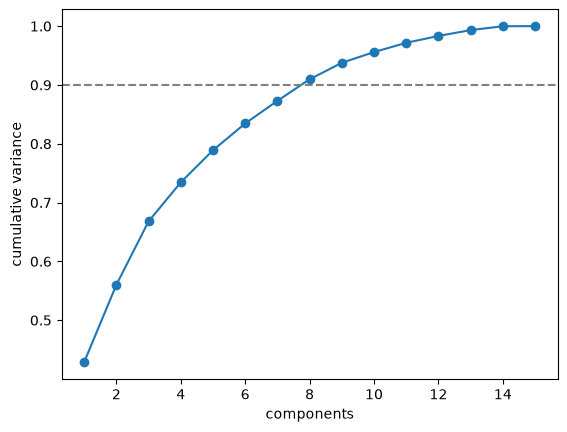

               PC1   PC2   PC3
PM2.5         0.37 -0.00  0.01
PM10          0.34 -0.21  0.06
NO            0.35  0.01  0.02
NO2           0.35 -0.11  0.10
NH3           0.28  0.09  0.20
SO2           0.21 -0.38  0.07
O3            0.09 -0.41  0.26
CO            0.26  0.14  0.24
Benzene       0.32  0.07  0.14
PM_ratio      0.22  0.41 -0.11
temp         -0.22 -0.40  0.22
rain         -0.20  0.33  0.27
wind_speed   -0.17 -0.35  0.01
wind_dir_sin -0.12  0.16  0.60
wind_dir_cos  0.14 -0.09 -0.55


In [4]:
from sklearn.decomposition import PCA

pca = PCA().fit(X_scaled)
cum = pca.explained_variance_ratio_.cumsum()
print(pd.Series(pca.explained_variance_ratio_, name="var").round(3).to_frame().assign(cum=cum.round(3)).head(8))

plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.9, ls="--", c="gray")
plt.xlabel("components"); plt.ylabel("cumulative variance"); plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=X_scaled.columns, columns=["PC1", "PC2", "PC3"]).round(2)
print(loadings)

## 5. Save scaled data and scaler

In [5]:
import joblib
(BASE / "models").mkdir(exist_ok=True)

X_scaled.to_csv(BASE / "data" / "features" / "delhi_scaled.csv")
joblib.dump(scaler, BASE / "models" / "scaler.pkl")
print("saved")

saved


## 6. Check: PM_ratio after capping
Range 0.17 to 1.00, skew reduced from 9.68 to 0.39.

In [6]:
r = feat["PM_ratio"]
print(r.describe().round(2))
print("days above 1:", (r > 1).sum())
print(r.sort_values().head(5).round(3))

count    1195.00
mean        0.49
std         0.14
min         0.17
25%         0.38
50%         0.47
75%         0.60
max         1.00
Name: PM_ratio, dtype: float64
days above 1: 0
Date
2020-05-28    0.170
2017-06-07    0.175
2020-06-28    0.193
2019-07-12    0.210
2019-06-29    0.214
Name: PM_ratio, dtype: float64


## 7. Save the 6-component PCA version
Keeps 83.5% of the variance.

In [7]:
pca6 = PCA(n_components=6).fit(X_scaled)
X_pca = pd.DataFrame(pca6.transform(X_scaled), index=X_scaled.index,
                     columns=[f"PC{i}" for i in range(1, 7)])
X_pca.to_csv(BASE / "data" / "features" / "delhi_pca.csv")
joblib.dump(pca6, BASE / "models" / "pca6.pkl")
print(pca6.explained_variance_ratio_.sum().round(3))     

0.835
